In [1]:
import pandas as pd
import requests

canarias = pd.read_csv("../data/raw/canarias_pm10_samplingpoints.csv")
print(len(canarias), "puntos de medición")

API = "https://eeadmz1-downloads-api-appservice.azurewebsites.net"

body = {
    "countries": ["ES"],
    "cities": [],
    "pollutants": ["PM10"],
    "dataset": 2,
    "source": "API",
}

r = requests.post(f"{API}/ParquetFile/urls", json=body, timeout=120)
print(r.status_code)

60 puntos de medición
200


In [2]:
print(r.text[:1500])

ï»¿ParquetFileUrl
https://eeadmz1batchservice02.blob.core.windows.net/airquality-p-e1a/ES/SP_01055001_10_47.parquet
https://eeadmz1batchservice02.blob.core.windows.net/airquality-p-e1a/ES/SP_01059009_10_47.parquet
https://eeadmz1batchservice02.blob.core.windows.net/airquality-p-e1a/ES/SP_01059012_10_47.parquet
https://eeadmz1batchservice02.blob.core.windows.net/airquality-p-e1a/ES/SP_03009006_10_M.parquet
https://eeadmz1batchservice02.blob.core.windows.net/airquality-p-e1a/ES/SP_03014006_10_M.parquet
https://eeadmz1batchservice02.blob.core.windows.net/airquality-p-e1a/ES/SP_03031002_10_46.parquet
https://eeadmz1batchservice02.blob.core.windows.net/airquality-p-e1a/ES/SP_03065007_10_M.parquet
https://eeadmz1batchservice02.blob.core.windows.net/airquality-p-e1a/ES/SP_03133002_10_46.parquet
https://eeadmz1batchservice02.blob.core.windows.net/airquality-p-e1a/ES/SP_03140001_10_46.parquet
https://eeadmz1batchservice02.blob.core.windows.net/airquality-p-e1a/ES/SP_04013004_10_49.parquet
https

In [3]:
from io import StringIO

texto = r.content.decode("utf-8-sig")          # bytes → texto, sin el BOM
urls = pd.read_csv(StringIO(texto))             # StringIO hace que un texto se lea como si fuera un archivo
urls["archivo"] = urls["ParquetFileUrl"].str.split("/").str[-1]   # solo el nombre del archivo

print(urls.shape)
urls.head()

(773, 2)


,ParquetFileUrl,archivo
0,https://eeadmz1batchservice02.blob.core.window...,SP_01055001_10_47.parquet
1,https://eeadmz1batchservice02.blob.core.window...,SP_01059009_10_47.parquet
2,https://eeadmz1batchservice02.blob.core.window...,SP_01059012_10_47.parquet
3,https://eeadmz1batchservice02.blob.core.window...,SP_03009006_10_M.parquet
4,https://eeadmz1batchservice02.blob.core.window...,SP_03014006_10_M.parquet


In [4]:
# 1. Sacar el código de 8 dígitos del nombre del archivo
urls["codigo"] = urls["archivo"].str.split("_").str[1]

# 2. Los códigos de tus estaciones de Canarias, como texto (para comparar texto con texto)
codigos_canarias = canarias["AirQualityStationNatCode"].astype(str)

# 3. Quedarse con las URLs cuyo código está en tu lista
urls_canarias = urls[urls["codigo"].isin(codigos_canarias)]

print(len(urls), "URLs de toda España")
print(len(urls_canarias), "URLs de Canarias")
urls_canarias.head()

773 URLs de toda España
105 URLs de Canarias


,ParquetFileUrl,archivo,codigo
251,https://eeadmz1batchservice02.blob.core.window...,SP_35002001_10_47.parquet,35002001
252,https://eeadmz1batchservice02.blob.core.window...,SP_35002001_10_A.parquet,35002001
254,https://eeadmz1batchservice02.blob.core.window...,SP_35004001_10_47.parquet,35004001
255,https://eeadmz1batchservice02.blob.core.window...,SP_35004001_10_A.parquet,35004001
256,https://eeadmz1batchservice02.blob.core.window...,SP_35004002_10_49.parquet,35004002


In [5]:
print(urls_canarias["codigo"].nunique(), "estaciones distintas")

urls_canarias["sufijo"] = urls_canarias["archivo"].str.split("_").str[3].str.replace(".parquet", "")
urls_canarias["sufijo"].value_counts()

47 estaciones distintas


sufijo
A     43
49    28
47    24
46    10
Name: count, dtype: int64

In [6]:
faltan = set(codigos_canarias) - set(urls_canarias["codigo"])
canarias[canarias["AirQualityStationNatCode"].astype(str).isin(faltan)][
    ["AirQualityStation", "AirQualityStationNatCode", "AirQualityStationType"]
].drop_duplicates("AirQualityStation")

,AirQualityStation,AirQualityStationNatCode,AirQualityStationType
0,STA-ES0197A,35026002,industrial
5,STA-ES1132A,38038011,industrial
7,STA-ES1133A,38011003,industrial
15,STA-ES1748A,35022001,industrial
17,STA-ES1757A,38038015,traffic


In [7]:
urls_por_prefijo = urls[urls["codigo"].str.startswith(("35", "38"))]
print(len(urls_por_prefijo), "URLs de Canarias filtrando directo")
print(urls_por_prefijo["codigo"].nunique(), "estaciones")

121 URLs de Canarias filtrando directo
56 estaciones


In [8]:
from pathlib import Path

destino = Path("../data/raw/eea_pm10")
destino.mkdir(parents=True, exist_ok=True)

def bajar(url):
    archivo = destino / url.split("/")[-1]   # mismo nombre que en la URL
    if not archivo.exists():                  # si ya lo tengo, no lo bajo de nuevo
        r = requests.get(url, timeout=120)
        r.raise_for_status()                  # si falla (404, 500...), que dé error y no guarde basura
        archivo.write_bytes(r.content)
    return archivo

prueba = urls_por_prefijo[urls_por_prefijo["codigo"] == "35002001"]
archivos = [bajar(u) for u in prueba["ParquetFileUrl"]]
archivos

[PosixPath('../data/raw/eea_pm10/SP_35002001_10_47.parquet'),
 PosixPath('../data/raw/eea_pm10/SP_35002001_10_A.parquet')]

In [9]:
for a in archivos:
    df = pd.read_parquet(a)
    print(a.name, "|", len(df), "filas |", df["Start"].min(), "→", df["Start"].max())

df.head()

SP_35002001_10_47.parquet | 34286 filas | 2013-01-01 01:00:00 → 2017-01-01 00:00:00
SP_35002001_10_A.parquet | 78144 filas | 2017-01-01 01:00:00 → 2026-01-01 00:00:00


,Samplingpoint,Pollutant,Start,End,Value,Unit,AggType,Validity,Verification,ResultTime,DataCapture,FkObservationLog
0,ES/SP_35002001_10_A,5,2017-01-01 01:00:00,2017-01-01 02:00:00,41.000000000000000000,ug.m-3,hour,1,1,2018-07-19 17:29:00,None,95656548-ac98-45c4-bb32-880b0fecb508
1,ES/SP_35002001_10_A,5,2017-01-01 02:00:00,2017-01-01 03:00:00,22.000000000000000000,ug.m-3,hour,1,1,2018-07-19 17:29:00,None,95656548-ac98-45c4-bb32-880b0fecb508
2,ES/SP_35002001_10_A,5,2017-01-01 03:00:00,2017-01-01 04:00:00,35.000000000000000000,ug.m-3,hour,1,1,2018-07-19 17:29:00,None,95656548-ac98-45c4-bb32-880b0fecb508
3,ES/SP_35002001_10_A,5,2017-01-01 04:00:00,2017-01-01 05:00:00,34.000000000000000000,ug.m-3,hour,1,1,2018-07-19 17:29:00,None,95656548-ac98-45c4-bb32-880b0fecb508
4,ES/SP_35002001_10_A,5,2017-01-01 05:00:00,2017-01-01 06:00:00,32.000000000000000000,ug.m-3,hour,1,1,2018-07-19 17:29:00,None,95656548-ac98-45c4-bb32-880b0fecb508


In [10]:
%%time
all_files = [bajar(u) for u in urls_por_prefijo["ParquetFileUrl"]]

CPU times: user 977 μs, sys: 1.46 ms, total: 2.43 ms
Wall time: 5.45 ms


In [11]:
len(list(destino.glob("*.parquet")))

121

In [12]:
sum([f.stat().st_size for f in all_files]) / 1_000_000

69.886637

In [13]:
def read_file(f: Path) -> pd.DataFrame:
    station_code = f.name.split("_")[1]   # "SP_35002001_10_A.parquet" → "35002001"
    df = pd.read_parquet(
        f,
        columns=["Start", "End", "Value", "Unit", "Validity", "Verification"],
    )
    df["station_code"] = station_code     # el mismo valor en todas las filas
    return df

In [14]:
read_file(all_files[0]).head()

,Start,End,Value,Unit,Validity,Verification,station_code
0,2013-01-01 01:00:00,2013-01-01 02:00:00,10.000000000000000000,ug.m-3,1,1,35002001
1,2013-01-01 02:00:00,2013-01-01 03:00:00,9.000000000000000000,ug.m-3,1,1,35002001
2,2013-01-01 03:00:00,2013-01-01 04:00:00,6.000000000000000000,ug.m-3,1,1,35002001
3,2013-01-01 04:00:00,2013-01-01 05:00:00,7.000000000000000000,ug.m-3,1,1,35002001
4,2013-01-01 05:00:00,2013-01-01 06:00:00,7.000000000000000000,ug.m-3,1,1,35002001


In [15]:
def read_file(f: Path) -> pd.DataFrame:
    parts = f.stem.split("_")       # "SP_35016012_10_A" → ["SP", "35016012", "10", "A"]
    df = pd.read_parquet(
        f,
        columns=["Start", "End", "Value", "Unit", "Validity", "Verification"],
    )
    df["Value"] = df["Value"].astype(float)
    df["station_code"] = parts[1]
    df["file_suffix"] = parts[3]
    return df

In [16]:
%%time
tables = [read_file(f) for f in all_files]
pm10 = pd.concat(tables, ignore_index=True)

CPU times: user 3.34 s, sys: 323 ms, total: 3.66 s
Wall time: 2.85 s


In [17]:
pm10.shape
pm10["station_code"].nunique()
pm10["Unit"].unique()

<ArrowStringArray>
['ug.m-3']
Length: 1, dtype: str

In [18]:
print(pm10.shape)
print(pm10["station_code"].nunique())
pm10["Unit"].unique()

(5468972, 8)
56


<ArrowStringArray>
['ug.m-3']
Length: 1, dtype: str

In [19]:
mask = pm10["Start"].between("2020-02-20", "2020-02-28")
feb_2020 = pm10[mask]
feb_2020.sort_values("Value", ascending=False).head(10)

,Start,End,Value,Unit,Validity,Verification,station_code,file_suffix
2787282,2020-02-22 19:00:00,2020-02-22 20:00:00,5254.0,ug.m-3,1,1,35002002,A
1078306,2020-02-22 19:00:00,2020-02-22 20:00:00,4985.0,ug.m-3,1,1,35019004,47
1078307,2020-02-22 20:00:00,2020-02-22 21:00:00,4867.0,ug.m-3,1,1,35019004,47
398015,2020-02-23 16:00:00,2020-02-23 17:00:00,4708.0,ug.m-3,1,1,35016010,49
2787303,2020-02-23 16:00:00,2020-02-23 17:00:00,4662.0,ug.m-3,1,1,35002002,A
1003026,2020-02-23 17:00:00,2020-02-23 18:00:00,4649.0,ug.m-3,1,1,35019002,A
1003025,2020-02-23 16:00:00,2020-02-23 17:00:00,4649.0,ug.m-3,1,1,35019002,A
3758348,2020-02-22 19:00:00,2020-02-22 20:00:00,4642.0,ug.m-3,1,1,35026004,49
3758369,2020-02-23 16:00:00,2020-02-23 17:00:00,4549.0,ug.m-3,1,1,35026004,49
2787304,2020-02-23 17:00:00,2020-02-23 18:00:00,4492.0,ug.m-3,1,1,35002002,A


<Axes: xlabel='Start'>

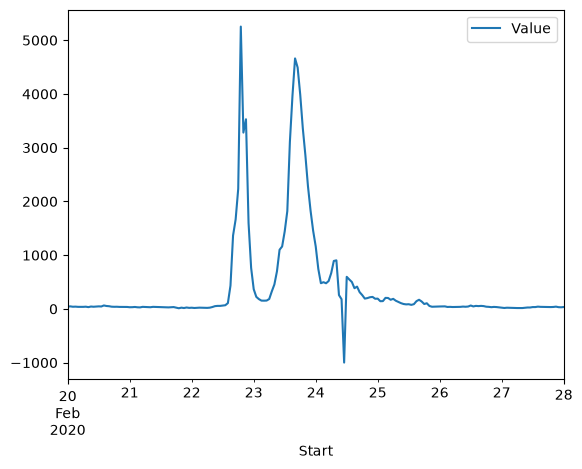

In [20]:
is_station = feb_2020["station_code"] == "35002002"
station = feb_2020[is_station]
station.plot(x="Start", y="Value")

In [21]:
is_negative = station["Value"] < 0
station[is_negative]

,Start,End,Value,Unit,Validity,Verification,station_code,file_suffix
2787322,2020-02-24 11:00:00,2020-02-24 12:00:00,-999.0,ug.m-3,-1,1,35002002,A


In [22]:
(pm10["Value"] < 0).sum()

np.int64(240096)

In [23]:
is_negative = pm10["Value"] < 0

In [24]:
negatives = pm10[is_negative]

In [25]:
negatives["Validity"].value_counts()

Validity
-1    240096
Name: count, dtype: int64

In [26]:
negatives["Value"].value_counts()

Value
-999.0    240096
Name: count, dtype: int64

In [27]:
is_positive = pm10["Value"] > 0

In [28]:
positives = pm10[is_positive]

In [29]:
positives["Validity"].value_counts()

Validity
1    5226731
Name: count, dtype: int64

In [30]:
total_validity = pm10["Validity"].value_counts()

In [31]:
total_validity

Validity
 1    5228876
-1     240096
Name: count, dtype: int64

In [32]:
(pm10["Value"] == 0).sum()

np.int64(2145)

In [33]:
(pm10["Value"]).isna().sum() 

np.int64(0)

<Axes: xlabel='Start'>

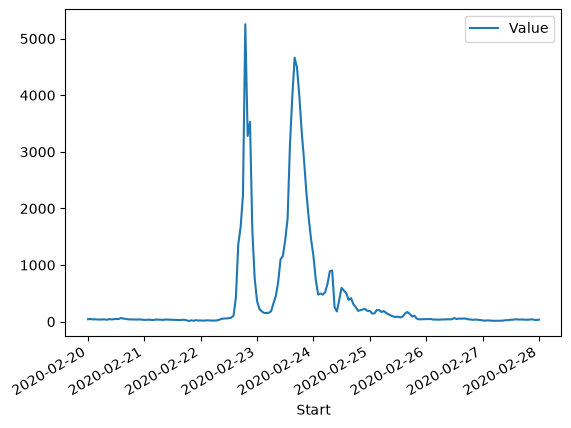

In [34]:
is_valid = pm10["Validity"] == 1
pm10_valid = pm10[is_valid]
mask = pm10_valid["Start"].between("2020-02-20", "2020-02-28")
valid_feb_2020 = pm10_valid[mask]
is_station = valid_feb_2020["station_code"] == "35002002"
station = valid_feb_2020[is_station]
station.plot(x="Start", y="Value")

In [35]:
pm10.duplicated(["station_code", "Start"]).sum()

np.int64(15165)

In [36]:
print(pm10_valid.duplicated(["station_code", "Start"]).sum())   # ¿quedan duplicados entre los válidos?
is_dup = pm10_valid.duplicated(["station_code", "Start"], keep=False)
pm10_valid[is_dup]["station_code"].value_counts()               # ¿en qué estaciones?

15165


station_code
35016012    12556
35024001     6294
35004001     6266
38011005     5214
Name: count, dtype: int64

## Duplicates

In [37]:
def read_file(f: Path) -> pd.DataFrame:
    parts = f.stem.split("_")       # "SP_35016012_10_A" → ["SP", "35016012", "10", "A"]
    df = pd.read_parquet(
        f,
        columns=["Start", "End", "Value", "Unit", "Validity", "Verification"],
    )
    df["Value"] = df["Value"].astype(float)
    df["station_code"] = parts[1]
    df["file_suffix"] = parts[3]
    return df

In [38]:
is_dup = pm10_valid.duplicated(["station_code", "Start"], keep=False)
dups = pm10_valid[is_dup]
dups.groupby(["station_code", "file_suffix"])["Start"].agg(["min", "max", "count"])

min                 max  count
station_code file_suffix                                               
35004001     47          2015-08-19 12:00:00 2016-01-01 00:00:00   3133
             49          2015-08-19 12:00:00 2016-01-01 00:00:00   3133
35016012     47          2015-02-17 01:00:00 2015-12-31 23:00:00   6278
             49          2015-02-17 01:00:00 2015-12-31 23:00:00   6278
35024001     47          2015-08-19 17:00:00 2016-01-01 00:00:00   3147
             49          2015-08-19 17:00:00 2016-01-01 00:00:00   3147
38011005     47          2015-09-11 01:00:00 2015-12-31 23:00:00   2607
             49          2015-09-11 01:00:00 2015-12-31 23:00:00   2607

In [39]:
pm10_valid.columns.tolist()

['Start',
 'End',
 'Value',
 'Unit',
 'Validity',
 'Verification',
 'station_code',
 'file_suffix']

In [40]:
four = ["35004001", "35016012", "35024001", "38011005"]
is_four = pm10_valid["station_code"].isin(four)
pm10_valid[is_four].groupby(["station_code", "file_suffix"])["Start"].agg(["min", "max"])

min                 max
station_code file_suffix                                        
35004001     47          2013-01-01 01:00:00 2016-01-01 00:00:00
             49          2015-08-19 12:00:00 2025-01-01 00:00:00
             A           2025-01-01 01:00:00 2026-01-01 00:00:00
35016012     47          2013-01-01 01:00:00 2015-12-31 23:00:00
             49          2015-02-17 01:00:00 2025-01-01 00:00:00
             A           2025-01-01 01:00:00 2026-01-01 00:00:00
35024001     47          2013-01-01 01:00:00 2016-01-01 00:00:00
             49          2015-08-19 17:00:00 2025-01-01 00:00:00
             A           2025-01-01 01:00:00 2026-01-01 00:00:00
38011005     47          2013-01-01 01:00:00 2015-12-31 23:00:00
             49          2015-09-11 01:00:00 2025-01-01 00:00:00
             A           2025-01-01 01:00:00 2026-01-01 00:00:00

In [41]:
is_duplicated_hour = pm10_valid.duplicated(["station_code", "Start"], keep=False)
is_old_equipment = pm10_valid["file_suffix"] == "47"
pm10_clean = pm10_valid[~(is_duplicated_hour & is_old_equipment)]

In [42]:
print(pm10_clean.duplicated(["station_code", "Start"]).sum())   # tiene que dar 0
print(len(pm10_valid) - len(pm10_clean))                        # tiene que dar 15165

0
15165
